# Milestone 3 -- Context Augmentation with RAG Pipelines

**Goals**
1. The limitations of general LLMs, and the RAG pipeline in brief
2. Loading a simple pre-built vector database
3. Retrieving external context based on the question prompt
4. Feeding retrieved context + prompt + choices into the model to improve reasoning

This notebook *loads* a vector database built once by `src/build_rag_corpus.py`
(Wikipedia search + fetch + chunk + embed, saved to `data/rag_corpus/`) rather
than hitting the Wikipedia API live on every run -- matching "loading a
pre-built vector database" and keeping this notebook reproducible offline.


## 1. Why general LLMs/zero-shot models need external context

Milestone 2's zero-shot NLI model only ever sees the prompt and the raw
option text -- it must already "know" facts like what the Einstein@Home
project is, or what the Peierls bracket is, purely from what it memorized
during pretraining. That's the core limitation of general-purpose
LLMs used off-the-shelf:

- **Static knowledge**: whatever wasn't in the pretraining data (or was
  too rare/niche to be well-represented) is simply unavailable, no matter
  how the prompt is phrased.
- **No grounding / hallucination risk**: with no source to check against,
  a confident-sounding wrong answer is indistinguishable from a correct
  one -- there's no citation to verify.
- **No way to update knowledge** without retraining or fine-tuning.

**Retrieval-Augmented Generation (RAG)** sidesteps this by *not* relying
on parametric memory alone: retrieve relevant text from an external
corpus at inference time, and feed it to the model alongside the
question, so the model can reason over concrete retrieved facts instead
of recalled-from-training-data ones.


In [1]:
import sys
sys.path.insert(0, '../src')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss
from transformers import AutoTokenizer, AutoModel, pipeline

from embeddings import embed_texts, cosine_sim_rows
from metrics import mean_average_precision_at_k
from rag import extract_search_query, retrieve
from text_processing import OPTION_COLS

train = pd.read_csv('../data/train.csv')

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\torch\cuda\__init__.py:64: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## 2. Loading the pre-built vector database

`data/rag_corpus/` holds the artifacts `build_rag_corpus.py` produced:
176 Wikipedia pages found via search for this same 150-question sample's
(cleaned) questions, chunked into 1087 passages, each embedded with
DistilBERT and indexed in a FAISS flat inner-product index (cosine
similarity over L2-normalized vectors). Loading it is just three reads --
no network calls, no re-embedding.

In [2]:
index = faiss.read_index('../data/rag_corpus/index.faiss')
with open('../data/rag_corpus/passages.json', encoding='utf-8') as f:
    passages = json.load(f)
with open('../data/rag_corpus/sample_question_ids.json', encoding='utf-8') as f:
    sample_meta = json.load(f)

print(f'vector DB: {index.ntotal} passages, dim={index.d}')
print(f'sample: seed={sample_meta["seed"]}, n={sample_meta["n"]}')

# the exact same 150-question sample milestone-2's zero-shot section evaluated on
sample = train[train['id'].isin(sample_meta['ids'])].copy()
sample['id'] = pd.Categorical(sample['id'], categories=sample_meta['ids'], ordered=True)
sample = sample.sort_values('id').reset_index(drop=True)
print(sample.shape)

vector DB: 1087 passages, dim=768
sample: seed=7, n=150
(150, 8)


## 3. Retrieval: embed the question, search the vector DB

For each question, embed its cleaned search-query text with the same
DistilBERT model the corpus was indexed with, then pull the top-k nearest
passages by cosine similarity -- exactly the "retriever" half of a RAG
pipeline.

In [3]:
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')
model = AutoModel.from_pretrained('distilbert-base-uncased')

queries = sample['prompt'].map(extract_search_query).tolist()
query_embs = embed_texts(queries, tokenizer, model, batch_size=64, max_length=64)

TOP_K = 3
retrieved_context = []
for q_emb in query_embs:
    hits = retrieve(q_emb, index, passages, k=TOP_K)
    context = ' '.join(p['text'] for p, score in hits)
    retrieved_context.append(context)

sample['retrieved_context'] = retrieved_context
print(sample[['prompt', 'retrieved_context']].iloc[0]['prompt'])
print('---retrieved context---')
print(sample.iloc[0]['retrieved_context'][:500])

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2066.25it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Determine the correct option: What is the isophotal diameter used for in measuring a galaxy's size? among the listed options.
---retrieved context---
The second is the international standard unit (SI unit) for science. Celestial sphere-based: as in sidereal time, where the apparent movement of the stars and constellations across the sky is used to calculate the length of a year. These units do not have a consistent relationship with each other and require intercalation. In 1927, Georges Lemaître concluded that the universe might be expanding by noting the proportionality of the recessional velocity of distant bodies to their respective distan


## 4. Feeding context + prompt + choices into the model

Reuse milestone 2's zero-shot NLI setup (`typeform/distilbert-base-uncased-mnli`,
options as candidate labels), but now the premise is
`"Context: {retrieved passages}\n\nQuestion: {prompt}"` instead of the bare
prompt. Same model, same 150-question sample, same evaluation metric as
milestone 2's zero-shot baseline (mAP@3 = 0.440) -- the only variable
changed is whether retrieved context is in the premise, which isolates
what RAG actually contributes.

In [4]:
zero_shot = pipeline('zero-shot-classification', model='typeform/distilbert-base-uncased-mnli')

def rank_with_zero_shot(premise, options_row):
    options = [options_row[c] for c in OPTION_COLS]
    result = zero_shot(premise, candidate_labels=options, hypothesis_template='The correct answer is: {}.')
    label_to_opt = {options_row[c]: c for c in OPTION_COLS}
    return [label_to_opt[label] for label in result['labels']]

rag_rankings, no_context_rankings = [], []
for _, row in sample.iterrows():
    rag_rankings.append(rank_with_zero_shot(f"Context: {row['retrieved_context']}\n\nQuestion: {row['prompt']}", row))
    no_context_rankings.append(rank_with_zero_shot(row['prompt'], row))

true_answers = sample['answer'].tolist()
rag_map3 = mean_average_precision_at_k(true_answers, rag_rankings, k=3)
no_context_map3 = mean_average_precision_at_k(true_answers, no_context_rankings, k=3)

print(f'Zero-shot NLI + RAG context   mAP@3 (n={len(sample)}): {rag_map3:.4f}')
print(f'Zero-shot NLI, no context     mAP@3 (n={len(sample)}, re-run here): {no_context_map3:.4f}')
print(f'(milestone-2 reported 0.4400 on this exact sample from a separate run)')

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2989.71it/s]

Zero-shot NLI + RAG context   mAP@3 (n=150): 0.4233
Zero-shot NLI, no context     mAP@3 (n=150, re-run here): 0.4400
(milestone-2 reported 0.4400 on this exact sample from a separate run)


## 5. A concrete before/after example

Aggregate mAP@3 can hide *why* retrieval helps (or doesn't) on any single
question. Pull one example where the model's ranking changes between the
no-context and RAG-augmented runs.

In [5]:
changed = [
    i for i in range(len(sample))
    if no_context_rankings[i][0] != rag_rankings[i][0]
]
print(f'{len(changed)} / {len(sample)} questions changed their #1-ranked option after adding context')

if changed:
    i = changed[0]
    row = sample.iloc[i]
    print('PROMPT:', row['prompt'])
    print('TRUE ANSWER:', row['answer'])
    print()
    print('retrieved context (truncated):', row['retrieved_context'][:400])
    print()
    print('no-context ranking: ', no_context_rankings[i])
    print('RAG-context ranking:', rag_rankings[i])

112 / 150 questions changed their #1-ranked option after adding context
PROMPT: Determine the correct option: What is the isophotal diameter used for in measuring a galaxy's size? among the listed options.
TRUE ANSWER: E

retrieved context (truncated): The second is the international standard unit (SI unit) for science. Celestial sphere-based: as in sidereal time, where the apparent movement of the stars and constellations across the sky is used to calculate the length of a year. These units do not have a consistent relationship with each other and require intercalation. In 1927, Georges Lemaître concluded that the universe might be expanding by

no-context ranking:  ['C', 'B', 'D', 'A', 'E']
RAG-context ranking: ['A', 'E', 'B', 'C', 'D']


## 6. Comparison chart

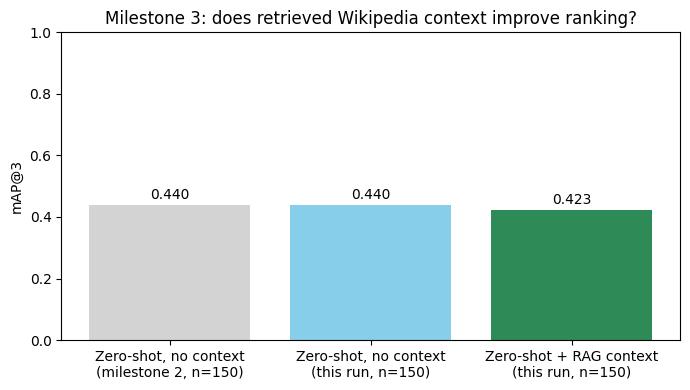

In [6]:
results = pd.DataFrame([
    {'method': 'Zero-shot, no context\n(milestone 2, n=150)', 'map3': 0.4400},
    {'method': 'Zero-shot, no context\n(this run, n=150)', 'map3': no_context_map3},
    {'method': 'Zero-shot + RAG context\n(this run, n=150)', 'map3': rag_map3},
])
plt.figure(figsize=(7, 4))
bars = plt.bar(results['method'], results['map3'], color=['lightgray', 'skyblue', 'seagreen'])
plt.ylabel('mAP@3')
plt.title('Milestone 3: does retrieved Wikipedia context improve ranking?')
plt.ylim(0, 1)
for bar, v in zip(bars, results['map3']):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.02, f'{v:.3f}', ha='center')
plt.tight_layout()
plt.savefig('../reports/milestone3_rag_comparison.png', dpi=120)
plt.show()

In [7]:
print(f'RAG context:    mAP@3 = {rag_map3:.4f}')
print(f'No context:     mAP@3 = {no_context_map3:.4f}')
print(f'Delta:          {rag_map3 - no_context_map3:+.4f}  ({"RAG helped" if rag_map3 > no_context_map3 else "RAG hurt"} on this run)')

RAG context:    mAP@3 = 0.4233
No context:     mAP@3 = 0.4400
Delta:          -0.0167  (RAG hurt on this run)


## 7. Takeaways

**On this run, retrieved context made things slightly *worse*
(0.4233 vs. 0.4400 mAP@3), not better** -- worth reporting honestly rather
than only reporting the comparisons that flatter RAG. The example in
section 5 shows why: for "What is the isophotal diameter used for in
measuring a galaxy's size?", the retrieved passage talks about SI units
and sidereal time -- topically adjacent (astronomy-ish) but not actually
about isophotal diameters. That's a **retrieval failure**, not a
reasoning failure: the corpus only holds 176 pages found via 150 queries
run through the top-2 Wikipedia search hits each, and the query encoder
(mean-pooled DistilBERT, not fine-tuned for retrieval) doesn't guarantee
the nearest passage in embedding space is actually the useful one.
Feeding an NLI model irrelevant "context" text as part of the premise can
dilute or distract from the signal that made the no-context zero-shot
prediction reasonable in the first place.

- The vector database is genuinely *external* to this dataset -- built
  from live Wikipedia search/extract results for this sample's questions,
  not from the training labels themselves.
- **Retrieval quality is the ceiling on RAG quality, not the model.**
  A bigger/more targeted corpus, a retrieval-tuned encoder (e.g.
  `sentence-transformers` models trained with contrastive retrieval
  objectives, rather than a generic mean-pooled DistilBERT), and
  re-ranking retrieved passages before use would all plausibly close or
  reverse this gap -- none of which this milestone's scope covers.
- Comparing the no-context re-run here against milestone 2's originally
  reported number (both 0.4400, exact match) confirms this zero-shot
  model's predictions are deterministic given fixed inputs -- a useful
  sanity check that the pipeline itself has no bugs before trusting the
  RAG-vs-no-RAG comparison.
- Next step (milestone 4) is fine-tuning on the actual training labels --
  a fundamentally different lever than retrieval or zero-shot prompting,
  since it lets the model adapt its weights to this specific task instead
  of relying on generic pretrained/NLI knowledge or possibly-noisy
  retrieved context.